## HEART HEALTH INFORMATION ASSISTANT

In [1]:
!pip install nltk scikit-learn pandas matplotlib seaborn gradio

   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.4 MB ? eta -:--:--
   - -------------------------------------- 1.0/31.4 MB 3.2 MB/s eta 0:00:10
   -- ------------------------------------- 2.1/31.4 MB 4.0 MB/s eta 0:00:08
   --- ------------------------------------ 2.9/31.4 MB 4.1 MB/s eta 0:00:07
   ----- ---------------------------------- 3.9/31.4 MB 4.3 MB/s eta 0:00:07
   ------ --------------------------------- 5.0/31.4 MB 4.5 MB/s eta 0:00:06
   ------- -------------------------------- 6.0/31.4 MB 4.4 MB/s eta 0:00:06
   ------- -------------------------------- 6.0/31.4 MB 4.4 MB/s eta 0:00:06
   -------- ------------------------------- 6.8/31.4 MB 3.8 MB/s eta 0:00:07
   --------- ------------------------------ 7.3/31.4 MB 3.6 MB/s eta 0:00:07
   ---------- ----------------------------- 8.4/31.4 MB 3.8 MB/s eta 0:00:07
   ----------- ---------------------------- 8.9/31.4 MB 3.8 MB/s eta 0:00:06
   ----------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opentelemetry-sdk 1.42.1 requires opentelemetry-api==1.42.1, but you have opentelemetry-api 1.45.2 which is incompatible.
opentelemetry-semantic-conventions 0.63b1 requires opentelemetry-api==1.42.1, but you have opentelemetry-api 1.45.2 which is incompatible.

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

data = {
    "query": [
        # SYMPTOMS
        "What are the symptoms of heart disease?",
        "Why do I experience chest discomfort?",
        "What are the warning signs of a heart problem?",
        "Can heart disease cause fatigue?",
        "Why does my heart beat irregularly?",
        "What are common signs of cardiovascular disease?",
        "Can heart problems cause dizziness?",
        "What does shortness of breath indicate?",

        # PREVENTION
        "How can I keep my heart healthy?",
        "What foods are good for heart health?",
        "How does exercise protect the heart?",
        "How can I prevent cardiovascular disease?",
        "Is walking beneficial for heart health?",
        "How much exercise is recommended for heart health?",
        "How can I reduce my heart disease risk?",
        "What lifestyle changes improve heart health?",

        # RISK FACTORS
        "Does smoking increase heart disease risk?",
        "Can high blood pressure affect the heart?",
        "Is diabetes a risk factor for heart disease?",
        "Does obesity increase cardiovascular risk?",
        "How does cholesterol affect the heart?",
        "Can family history cause heart disease?",
        "Does stress affect cardiovascular health?",
        "What are the major risk factors for heart disease?",

        # DIAGNOSIS
        "What is an ECG test?",
        "How does an echocardiogram work?",
        "What is a cholesterol blood test?",
        "How is heart disease diagnosed?",
        "Why is a stress test performed?",
        "What is an angiography test?",
        "How do doctors check heart function?",
        "What is an echocardiogram used for?",

        # MANAGEMENT
        "How can high blood pressure be managed?",
        "What diet is recommended for heart patients?",
        "How can cholesterol be controlled?",
        "What lifestyle changes help heart patients?",
        "Why is regular exercise important after diagnosis?",
        "How should heart patients monitor their health?",
        "What is cardiac rehabilitation?",
        "How can I maintain a healthy blood pressure?",

        # EMERGENCY
        "I have severe chest pain right now.",
        "I am experiencing sudden difficulty breathing.",
        "Someone has collapsed and is unconscious.",
        "I have sudden weakness on one side of my body.",
        "I have chest pain and cold sweating.",
        "Someone is having severe breathing problems.",
        "I feel faint and have severe chest discomfort.",
        "A person is unresponsive and not breathing normally."
    ],

    "intent": (
        ["symptoms"] * 8 +
        ["prevention"] * 8 +
        ["risk_factors"] * 8 +
        ["diagnosis"] * 8 +
        ["management"] * 8 +
        ["emergency"] * 8
    )
}

df = pd.DataFrame(data)

print("Dataset:")
display(df.head(10))

print("\nTotal Queries:", len(df))

print("\nIntent Distribution:")
print(df["intent"].value_counts())

Dataset:


,query,intent
0,What are the symptoms of heart disease?,symptoms
1,Why do I experience chest discomfort?,symptoms
2,What are the warning signs of a heart problem?,symptoms
3,Can heart disease cause fatigue?,symptoms
4,Why does my heart beat irregularly?,symptoms
5,What are common signs of cardiovascular disease?,symptoms
6,Can heart problems cause dizziness?,symptoms
7,What does shortness of breath indicate?,symptoms
8,How can I keep my heart healthy?,prevention
9,What foods are good for heart health?,prevention



Total Queries: 48

Intent Distribution:
intent
symptoms        8
prevention      8
risk_factors    8
diagnosis       8
management      8
emergency       8
Name: count, dtype: int64


## hierarchical taxonomy

In [3]:
taxonomy = {
    "Heart Health": {
        "Symptoms": [
            "Physical symptoms",
            "Cardiac warning signs"
        ],

        "Prevention": [
            "Diet and nutrition",
            "Physical activity"
        ],

        "Risk Factors": [
            "Lifestyle risk factors",
            "Medical and genetic risk factors"
        ],

        "Medical Care": [
            "Diagnosis and tests",
            "Treatment and management"
        ]
    }
}

for category, subcategories in taxonomy.items():
    print("\n", category)

    for subcategory, topics in subcategories.items():
        print(" ", subcategory)

        for topic in topics:
            print("    -", topic)


 Heart Health
  Symptoms
    - Physical symptoms
    - Cardiac warning signs
  Prevention
    - Diet and nutrition
    - Physical activity
  Risk Factors
    - Lifestyle risk factors
    - Medical and genetic risk factors
  Medical Care
    - Diagnosis and tests
    - Treatment and management


In [4]:
# Domain concepts
concepts = {
    "Heart": "Organ responsible for pumping blood",
    "Blood Pressure": "Force exerted by blood against artery walls",
    "Cholesterol": "Fat-like substance present in blood",
    "ECG": "Test that records electrical activity of the heart",
    "Exercise": "Physical activity supporting cardiovascular health",
    "Smoking": "Lifestyle factor that increases cardiovascular risk",
    "Diabetes": "Condition associated with increased cardiovascular risk",
    "Obesity": "Excess body fat associated with cardiovascular risk",
    "Diet": "Food habits affecting cardiovascular health",
    "Angiography": "Imaging test used to examine blood vessels",
    "Heart Disease": "Conditions affecting heart structure or function",
    "Cardiac Rehabilitation": "Supervised recovery and support program"
}

print("DOMAIN CONCEPTS")

for concept, description in concepts.items():
    print(concept, ":", description)


# Relationships between concepts
relationships = [
    ("Smoking", "increases risk of", "Heart Disease"),
    ("Diabetes", "increases risk of", "Heart Disease"),
    ("Obesity", "increases risk of", "Heart Disease"),
    ("High Blood Pressure", "affects", "Heart"),
    ("Cholesterol", "can contribute to", "Artery Blockage"),
    ("Exercise", "supports", "Heart Health"),
    ("Diet", "influences", "Cholesterol"),
    ("ECG", "examines", "Heart Electrical Activity"),
    ("Angiography", "examines", "Blood Vessels"),
    ("Heart Disease", "may require", "Medical Treatment"),
    ("Cardiac Rehabilitation", "supports recovery from", "Heart Disease"),
    ("Diabetes", "requires monitoring of", "Blood Glucose")
]

print("\nDOMAIN RELATIONSHIPS")

for relation in relationships:
    print(relation[0], "-->", relation[1], "-->", relation[2])

print("\nTotal Concepts:", len(concepts))
print("Total Relationships:", len(relationships))


DOMAIN CONCEPTS
Heart : Organ responsible for pumping blood
Blood Pressure : Force exerted by blood against artery walls
Cholesterol : Fat-like substance present in blood
ECG : Test that records electrical activity of the heart
Exercise : Physical activity supporting cardiovascular health
Smoking : Lifestyle factor that increases cardiovascular risk
Diabetes : Condition associated with increased cardiovascular risk
Obesity : Excess body fat associated with cardiovascular risk
Diet : Food habits affecting cardiovascular health
Angiography : Imaging test used to examine blood vessels
Heart Disease : Conditions affecting heart structure or function
Cardiac Rehabilitation : Supervised recovery and support program

DOMAIN RELATIONSHIPS
Smoking --> increases risk of --> Heart Disease
Diabetes --> increases risk of --> Heart Disease
Obesity --> increases risk of --> Heart Disease
High Blood Pressure --> affects --> Heart
Cholesterol --> can contribute to --> Artery Blockage
Exercise --> suppo

text preprocessing

In [5]:
import nltk
import re

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english'))

# Preserve negation words
stop_words = stop_words - {"no", "not", "never", "nor"}

lemmatizer = WordNetLemmatizer()


def preprocess_text(text):

    # Lowercase conversion
    text = text.lower()

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Tokenization
    tokens = nltk.wordpunct_tokenize(text)

    # Stopword removal and lemmatization
    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 1
    ]

    return " ".join(cleaned_tokens)


# Apply preprocessing
df["cleaned_query"] = df["query"].apply(preprocess_text)

print(df[["query", "cleaned_query"]].head(10))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Maansi\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Maansi\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Maansi\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


                                              query  \
0           What are the symptoms of heart disease?   
1             Why do I experience chest discomfort?   
2    What are the warning signs of a heart problem?   
3                  Can heart disease cause fatigue?   
4               Why does my heart beat irregularly?   
5  What are common signs of cardiovascular disease?   
6               Can heart problems cause dizziness?   
7           What does shortness of breath indicate?   
8                  How can I keep my heart healthy?   
9             What foods are good for heart health?   

                        cleaned_query  
0               symptom heart disease  
1         experience chest discomfort  
2          warning sign heart problem  
3         heart disease cause fatigue  
4              heart beat irregularly  
5  common sign cardiovascular disease  
6       heart problem cause dizziness  
7           shortness breath indicate  
8                  keep heart heal

TF-IDF 

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

# Input and output
X = df["cleaned_query"]
y = df["intent"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Create ML pipeline
model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=2000,
            sublinear_tf=True
        )
    ),

    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

# Train model
model.fit(X_train, y_train)

print("Model training completed successfully!")

# Predict test data
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

Model training completed successfully!

Model Accuracy: 50.0 %


model evaluation


CLASSIFICATION REPORT

              precision    recall  f1-score   support

   diagnosis       0.00      0.00      0.00         2
   emergency       0.67      1.00      0.80         2
  management       1.00      0.50      0.67         2
  prevention       0.50      0.50      0.50         2
risk_factors       0.50      1.00      0.67         2
    symptoms       0.00      0.00      0.00         2

    accuracy                           0.50        12
   macro avg       0.44      0.50      0.44        12
weighted avg       0.44      0.50      0.44        12



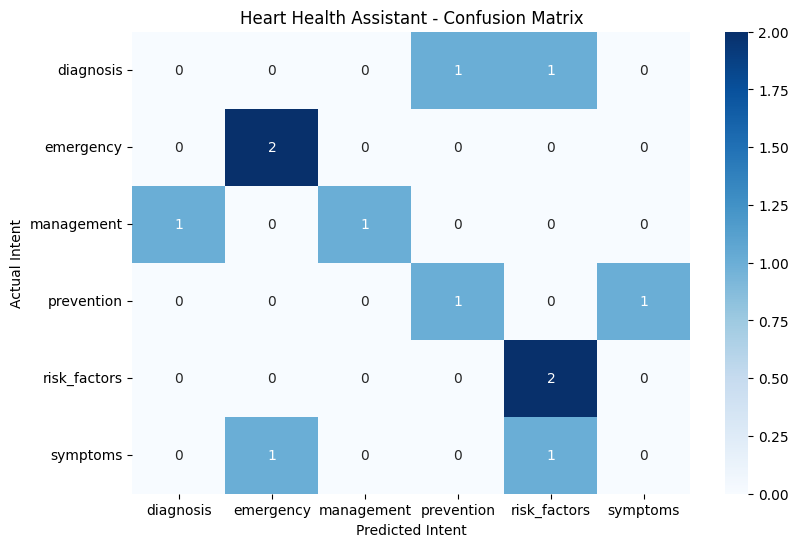

In [7]:
# Classification report
print("\nCLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Heart Health Assistant - Confusion Matrix")

plt.show()

domain specific knowledge base


In [8]:
knowledge_base = {

    "symptoms": """
    Common warning signs of heart-related conditions may include
    chest discomfort, breathlessness, unusual fatigue, palpitations
    and dizziness. Symptoms vary between individuals.
    Some heart conditions may have no obvious symptoms.
    """,

    "prevention": """
    Heart health can be supported through regular physical activity,
    a balanced diet, adequate sleep, avoiding tobacco, limiting
    excess salt and managing stress. Regular health checkups
    are also important.
    """,

    "risk_factors": """
    Important cardiovascular risk factors include high blood pressure,
    high cholesterol, diabetes, smoking, obesity, physical inactivity,
    unhealthy diet, age and family history.
    """,

    "diagnosis": """
    Doctors may use ECG, echocardiography, blood tests, stress tests
    and coronary angiography to evaluate heart health.
    The choice of test depends on symptoms and medical history.
    """,

    "management": """
    Heart health management may include prescribed medication,
    dietary changes, physical activity, blood pressure monitoring,
    cholesterol management and cardiac rehabilitation.
    Follow the advice of a qualified healthcare professional.
    """,

    "emergency": """
    Severe chest pain, serious breathing difficulty, fainting,
    or sudden stroke-like symptoms require immediate medical attention.
    Call emergency services immediately.
    """
}

print("Knowledge Base Created Successfully!")

for intent, information in knowledge_base.items():
    print("\n", intent.upper())
    print(information)

Knowledge Base Created Successfully!

 SYMPTOMS

    Common warning signs of heart-related conditions may include
    chest discomfort, breathlessness, unusual fatigue, palpitations
    and dizziness. Symptoms vary between individuals.
    Some heart conditions may have no obvious symptoms.
    

 PREVENTION

    Heart health can be supported through regular physical activity,
    a balanced diet, adequate sleep, avoiding tobacco, limiting
    excess salt and managing stress. Regular health checkups
    are also important.
    

 RISK_FACTORS

    Important cardiovascular risk factors include high blood pressure,
    high cholesterol, diabetes, smoking, obesity, physical inactivity,
    unhealthy diet, age and family history.
    

 DIAGNOSIS

    Doctors may use ECG, echocardiography, blood tests, stress tests
    and coronary angiography to evaluate heart health.
    The choice of test depends on symptoms and medical history.
    

 MANAGEMENT

    Heart health management may include

rule based reasoning

In [9]:
import re

# Emergency keywords and patterns
emergency_patterns = [
    r'\bsevere chest pain\b',
    r'\bchest pain\b',
    r'\bheart attack\b',
    r'\bnot breathing\b',
    r'\bunconscious\b',
    r'\bsevere breathing difficulty\b',
    r'\bdifficulty breathing\b',
    r'\bshortness of breath\b',
    r'\bfaint(?:ing|ed)?\b',
    r'\bstroke\b',
    r'\bone[- ]sided weakness\b',
    r'\bface drooping\b',
    r'\bcold sweating\b'
]


def check_emergency(query):

    query = query.lower()

    for pattern in emergency_patterns:
        if re.search(pattern, query):
            return True

    return False


def cognitive_assistant(query):

    # Rule 1: Emergency escalation
    if check_emergency(query):

        return """
        🚨 EMERGENCY ALERT

        Your query mentions potentially serious warning signs.

        Please seek immediate medical attention.
        Call 112 in India or your local emergency number.

        Do not wait for an AI response or attempt self-diagnosis.
        """

    # Preprocess query
    cleaned_query = preprocess_text(query)

    if not cleaned_query.strip():
        return "Please enter a valid healthcare question."

    # Convert query into TF-IDF features
    vector = model.named_steps["tfidf"].transform(
        [cleaned_query]
    )

    # Rule 2: Unsupported query
    if vector.nnz == 0:

        return """
        UNSUPPORTED QUERY

        I can only answer questions related to heart health.

        Please ask about symptoms, prevention, risk factors,
        diagnosis or management.
        """

    # Predict intent and confidence
    probabilities = model.predict_proba(
        [cleaned_query]
    )[0]

    predicted_index = probabilities.argmax()

    intent = model.classes_[predicted_index]

    confidence = probabilities[predicted_index]

    # Rule 3: Low-confidence handling
    if confidence < 0.30:

        return """
        LOW CONFIDENCE QUERY

        I could not confidently understand your question.

        Please rephrase your question using more specific
        heart-health terms.
        """

    # Retrieve information from knowledge base
    response = knowledge_base[intent]

    # Rule 4: Intent-based response
    result = f"""
    ❤️ HEART HEALTH COGNITIVE ASSISTANT

    Your Query: {query}

    Detected Intent: {intent.upper()}

    Confidence: {confidence:.2f}

    Relevant Information:
    {response}

    """

    # Rule 5: Medical disclaimer
    result += """
    DISCLAIMER:
    This assistant provides general educational information.
    It does not diagnose medical conditions or replace
    professional medical advice.
    """

    return result


print(cognitive_assistant(
    "What are the symptoms of heart disease?"
))


        LOW CONFIDENCE QUERY

        I could not confidently understand your question.

        Please rephrase your question using more specific
        heart-health terms.
        


Integrate everything into an interactive assistant

In [10]:
import gradio as gr


def process_multiple_queries(user_input):

    # Split input into separate queries
    queries = [
        q.strip()
        for q in user_input.split("\n")
        if q.strip()
    ]

    if not queries:
        return "Please enter at least one query."

    results = []

    for i, query in enumerate(queries, start=1):

        response = cognitive_assistant(query)

        results.append(
            f"QUERY {i}\n"
            f"{'=' * 45}\n"
            f"{response}"
        )

    return "\n\n".join(results)


# Create Gradio interface
with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown(
        """
        # ❤️ Heart Health Cognitive Assistant

        ### UCS420 - Cognitive Computing Assignment 10

        Ask questions about heart health, symptoms,
        prevention, risk factors, diagnosis and management.

        You can enter multiple queries, one per line.
        """
    )

    user_input = gr.Textbox(
        label="Enter Your Healthcare Queries",
        placeholder=(
            "What are the symptoms of heart disease?\n"
            "How can I keep my heart healthy?"
        ),
        lines=5
    )

    submit_button = gr.Button(
        "Get Healthcare Information",
        variant="primary"
    )

    output = gr.Textbox(
        label="Assistant Response",
        lines=15
    )

    submit_button.click(
        fn=process_multiple_queries,
        inputs=user_input,
        outputs=output
    )

demo.launch(share=True)

c:\Users\Maansi\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Maansi\AppData\Local\Temp\ipykernel_2516\3650108867.py:32: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://9329e987849e746740.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Test the assistant with the five required test cases

In [11]:
test_cases = [

    # 1. Query belonging to each defined intent
    "What are the symptoms of heart disease?",
    "How can I prevent heart disease?",
    "Does smoking increase heart disease risk?",
    "What is an ECG test?",
    "How can high blood pressure be managed?",
    "I have severe chest pain right now.",

    # 2. Differently worded query
    "What should I do to take better care of my heart?",

    # 3. Unsupported healthcare query
    "What is the weather forecast for tomorrow?",

    # 4. Low-confidence query
    "Heart issue",

    # 5. Emergency-related query
    "I am having chest pain and difficulty breathing."
]

for i, query in enumerate(test_cases, start=1):

    print("\n" + "=" * 60)
    print("TEST CASE", i)
    print("USER QUERY:", query)
    print("=" * 60)

    print(cognitive_assistant(query))


TEST CASE 1
USER QUERY: What are the symptoms of heart disease?

        LOW CONFIDENCE QUERY

        I could not confidently understand your question.

        Please rephrase your question using more specific
        heart-health terms.
        

TEST CASE 2
USER QUERY: How can I prevent heart disease?

        LOW CONFIDENCE QUERY

        I could not confidently understand your question.

        Please rephrase your question using more specific
        heart-health terms.
        

TEST CASE 3
USER QUERY: Does smoking increase heart disease risk?

    ❤️ HEART HEALTH COGNITIVE ASSISTANT

    Your Query: Does smoking increase heart disease risk?

    Detected Intent: RISK_FACTORS

    Confidence: 0.34

    Relevant Information:
    
    Important cardiovascular risk factors include high blood pressure,
    high cholesterol, diabetes, smoking, obesity, physical inactivity,
    unhealthy diet, age and family history.
    

    
    DISCLAIMER:
    This assistant provides general ed